 #### YOLOv8/v11 Hand Detection - Mixed Dataset Training

This notebook trains a YOLO model for hand detection using **multiple diverse datasets** to improve generalization across different viewpoints (egocentric, third-person, TV, etc.).
 Datasets Used:
1. **EgoHands** (~4,800 images) - Egocentric/first-person perspective
2. **Oxford Hand Dataset** (~13,000 images) - Third-person, varied scenes
3. **HaGRID subset** (optional) - Hand gestures with bounding boxes
 Notebook Structure:
1. Setup & Configuration
2. Dataset Downloads
3. Dataset Conversion to YOLO Format
4. Dataset Merging & Split Creation
5. Visualization & Statistics
6. Training Configuration
7. Model Training
8. Evaluation & Metrics
9. Inference & Testing

 ### 1. Setup & Configuration

In [5]:
# ============================================================================
# 1.1 Environment Detection & Dependencies
# ============================================================================
# Detect environment
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print(f"Running in Colab: {IN_COLAB}")
# Install dependencies if in Colab
if IN_COLAB:
    !pip install -q ultralytics kagglehub thop
# Core imports
import os
import sys
import time
import shutil
import random
import zipfile
import urllib.request
from pathlib import Path
from glob import glob
from typing import List, Dict, Tuple, Optional
# Data processing
import numpy as np
import pandas as pd
import scipy.io as sio
import xml.etree.ElementTree as ET
import yaml
import json
# Deep Learning
import torch
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
# YOLO
from ultralytics import YOLO
# Kaggle
try:
    import kagglehub
    KAGGLE_AVAILABLE = True
except ImportError:
    KAGGLE_AVAILABLE = False
    print("⚠️ kagglehub not installed. Run: pip install kagglehub")
# Device info
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Running in Colab: False
PyTorch version: 2.9.1+cu128
Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [6]:
# ============================================================================
# 1.2 Project Configuration
# ============================================================================
# Random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# ---------------------- PATH CONFIGURATION ----------------------
if IN_COLAB:
    PROJECT_ROOT = Path("/content/hand_detection")
else:
    PROJECT_ROOT = Path.cwd() / "hand_bbox_baseline"
# Directory structure
DATA_ROOT = PROJECT_ROOT / "data"
RAW_DIR = DATA_ROOT / "raw"           # Downloaded datasets
WORK_DIR = DATA_ROOT / "work"         # Intermediate processing
YOLO_DIR = DATA_ROOT / "hands_yolo"   # Final YOLO dataset
RUNS_DIR = PROJECT_ROOT / "runs"      # Training outputs
# Create directories
for d in [RAW_DIR, WORK_DIR, YOLO_DIR, RUNS_DIR]:
    d.mkdir(parents=True, exist_ok=True)
# ---------------------- DATASET CONFIGURATION ----------------------
DATASETS_CONFIG = {
    "egohands": {
        "enabled": True,
        "kaggle_id": "himaniishah/egohands",
        "description": "Egocentric hand detection (~4,800 images)",
        "perspective": "egocentric"
    },
    "oxford_hand": {
        "enabled": True,
        "kaggle_id": "armannikkhah/hand-dataset",
        "description": "Oxford/Kaggle hand dataset (~13,000 images)",
        "perspective": "third_person"
    },
    "hagrid": {
        "enabled": True,  # Optional - large dataset
        "kaggle_id": "innominate817/hagrid-sample-30k-384p",
        "description": "HaGRID gesture dataset sample",
        "perspective": "third_person"
    },
    "tv_hand": {
        "enabled": False,  
        "kaggle_id": "victordibia/hand-dataset",
        "description": "TV-Hand dataset (~5k images)",
        "perspective": "third_person"
    }
}
# ---------------------- TRAINING CONFIGURATION ----------------------
TRAINING_CONFIG = {
    "img_size": 640,          # Image size (640 recommended for YOLOv8)
    "batch_size": 16,         # Adjust based on GPU memory
    "epochs": 100,            # Training epochs
    "patience": 20,           # Early stopping patience
    "optimizer": "AdamW",
    "base_model": "yolov8n.pt",  # Options: yolov8n.pt, yolov8s.pt, yolo11n.pt
}
# ---------------------- SPLIT CONFIGURATION ----------------------
SPLIT_CONFIG = {
    "train_ratio": 0.8,
    "val_ratio": 0.1,
    "test_ratio": 0.1,
}
print("=" * 60)
print("PROJECT CONFIGURATION")
print("=" * 60)
print(f"Project root: {PROJECT_ROOT}")
print(f"YOLO dataset: {YOLO_DIR}")
print(f"Training runs: {RUNS_DIR}")
print(f"\nEnabled datasets:")
for name, cfg in DATASETS_CONFIG.items():
    if cfg["enabled"]:
        print(f"  ✓ {name}: {cfg['description']}")


PROJECT CONFIGURATION
Project root: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline
YOLO dataset: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo
Training runs: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/runs

Enabled datasets:
  ✓ egohands: Egocentric hand detection (~4,800 images)
  ✓ oxford_hand: Oxford/Kaggle hand dataset (~13,000 images)
  ✓ hagrid: HaGRID gesture dataset sample


### 2. Dataset Downloads

In [7]:
# ============================================================================
# 2.1 Download Helper Functions
# ============================================================================
def download_from_kaggle(dataset_id: str, dest_dir: Path, dataset_name: str) -> Path:
    """Download dataset from Kaggle using kagglehub."""
    if not KAGGLE_AVAILABLE:
        raise ImportError("kagglehub is required. Install with: pip install kagglehub")
    
    dest_dir = Path(dest_dir)
    final_path = dest_dir / dataset_name
    
    if final_path.exists() and any(final_path.iterdir()):
        print(f"✓ {dataset_name} already exists at {final_path}")
        return final_path
    
    print(f"⬇️ Downloading {dataset_name} from Kaggle...")
    cache_path = Path(kagglehub.dataset_download(dataset_id))
    print(f"  Downloaded to cache: {cache_path}")
    
    # Copy to our directory
    if final_path.exists():
        shutil.rmtree(final_path)
    shutil.copytree(cache_path, final_path)
    print(f"✓ Copied to {final_path}")
    
    return final_path
def download_from_url(url: str, dest_path: Path, extract: bool = True) -> Path:
    """Download file from URL and optionally extract."""
    dest_path = Path(dest_path)
    
    if dest_path.exists():
        print(f"✓ Already exists: {dest_path}")
        return dest_path
    
    dest_path.parent.mkdir(parents=True, exist_ok=True)
    
    print(f"⬇️ Downloading from {url}...")
    zip_path = dest_path.parent / (dest_path.name + ".zip")
    urllib.request.urlretrieve(url, zip_path)
    
    if extract and zip_path.suffix == ".zip":
        print(f"  Extracting to {dest_path}...")
        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(dest_path)
        zip_path.unlink()
    
    print(f"✓ Downloaded to {dest_path}")
    return dest_path

In [8]:
# ============================================================================
# 2.2 Download All Enabled Datasets
# ============================================================================
downloaded_paths = {}
# Download EgoHands
if DATASETS_CONFIG["egohands"]["enabled"]:
    egohands_path = download_from_kaggle(
        DATASETS_CONFIG["egohands"]["kaggle_id"],
        WORK_DIR,
        "egohands"
    )
    downloaded_paths["egohands"] = egohands_path
# Download Oxford Hand Dataset
if DATASETS_CONFIG["oxford_hand"]["enabled"]:
    oxford_path = download_from_kaggle(
        DATASETS_CONFIG["oxford_hand"]["kaggle_id"],
        RAW_DIR,
        "oxford_hand"
    )
    downloaded_paths["oxford_hand"] = oxford_path
# Download HaGRID
if DATASETS_CONFIG["hagrid"]["enabled"]:
    hagrid_path = download_from_kaggle(
        DATASETS_CONFIG["hagrid"]["kaggle_id"],
        RAW_DIR,
        "hagrid"
    )
    downloaded_paths["hagrid"] = hagrid_path
# Download TV-Hand
if DATASETS_CONFIG["tv_hand"]["enabled"]:
    tv_hand_path = download_from_kaggle(
        DATASETS_CONFIG["tv_hand"]["kaggle_id"],
        RAW_DIR,
        "tv_hand"
    )
    downloaded_paths["tv_hand"] = tv_hand_path
print("\n" + "=" * 60)
print("DOWNLOADED DATASETS")
print("=" * 60)
for name, path in downloaded_paths.items():
    print(f"  {name}: {path}")

✓ egohands already exists at /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/work/egohands
✓ oxford_hand already exists at /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/raw/oxford_hand
✓ hagrid already exists at /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/raw/hagrid

DOWNLOADED DATASETS
  egohands: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/work/egohands
  oxford_hand: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/raw/oxford_hand
  hagrid: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/raw/hagrid


In [9]:
# ============================================================================
# 2.3 Explore Dataset Structure
# ============================================================================
def explore_directory(path: Path, max_depth: int = 2, current_depth: int = 0):
    """Print directory structure."""
    if current_depth >= max_depth:
        return
    
    indent = "  " * current_depth
    
    if path.is_file():
        print(f"{indent}📄 {path.name}")
    else:
        print(f"{indent}📁 {path.name}/")
        try:
            items = sorted(path.iterdir())[:10]  # Limit to first 10 items
            for item in items:
                explore_directory(item, max_depth, current_depth + 1)
            if len(list(path.iterdir())) > 10:
                print(f"{indent}  ... and more")
        except PermissionError:
            print(f"{indent}  (permission denied)")
print("Dataset structures:\n")
for name, path in downloaded_paths.items():
    print(f"\n{'='*40}")
    print(f"{name.upper()}")
    print(f"{'='*40}")
    explore_directory(path, max_depth=3)

Dataset structures:


EGOHANDS
📁 egohands/
  📄 DEMO_1.m
  📄 DEMO_2.m
  📄 README.txt
  📁 _LABELLED_SAMPLES/
    📁 CARDS_COURTYARD_B_T/
      ... and more
    📁 CARDS_COURTYARD_H_S/
      ... and more
    📁 CARDS_COURTYARD_S_H/
      ... and more
    📁 CARDS_COURTYARD_T_B/
      ... and more
    📁 CARDS_LIVINGROOM_B_T/
      ... and more
    📁 CARDS_LIVINGROOM_H_S/
      ... and more
    📁 CARDS_LIVINGROOM_S_H/
      ... and more
    📁 CARDS_LIVINGROOM_T_B/
      ... and more
    📁 CARDS_OFFICE_B_S/
      ... and more
    📁 CARDS_OFFICE_H_T/
      ... and more
    ... and more
  📄 getBoundingBoxes.m
  📄 getFramePath.m
  📄 getMetaBy.m
  📄 getSegmentationMask.m
  📄 metadata.mat
  📄 showLabelsOnFrame.m

OXFORD_HAND
📁 oxford_hand/
  📁 hand_dataset/
    📄 ._README.txt
    📄 README.txt
    📁 evaluation_code/
      ... and more
    📁 test_dataset/
    📁 training_dataset/
    📁 validation_dataset/

HAGRID
📁 hagrid/
  📁 hagrid-sample-30k-384p/
    📁 ann_train_val/
      ... and more
    📁 hagrid_

### 3. Dataset Conversion to YOLO Format
Each dataset has different annotation formats. We'll convert them all to YOLO format:
- **YOLO format**: `class_id center_x center_y width height` (normalized 0-1)
- **Class**: 0 = hand (single class detection)

In [10]:
# ============================================================================
# 3.1 Conversion Utility Functions
# ============================================================================
def bbox_to_yolo(x1: float, y1: float, x2: float, y2: float, 
                 img_w: int, img_h: int) -> Tuple[float, float, float, float]:
    """Convert pixel bbox (x1,y1,x2,y2) to YOLO format (cx,cy,w,h) normalized."""
    cx = (x1 + x2) / 2.0 / img_w
    cy = (y1 + y2) / 2.0 / img_h
    w = (x2 - x1) / img_w
    h = (y2 - y1) / img_h
    
    # Clamp to valid range
    cx = np.clip(cx, 0, 1)
    cy = np.clip(cy, 0, 1)
    w = np.clip(w, 0, 1)
    h = np.clip(h, 0, 1)
    
    return cx, cy, w, h
def polygon_to_bbox(points: np.ndarray) -> Tuple[float, float, float, float]:
    """Convert polygon points to bounding box (x1,y1,x2,y2)."""
    xs = points[:, 0]
    ys = points[:, 1]
    return xs.min(), ys.min(), xs.max(), ys.max()
def is_valid_bbox(cx: float, cy: float, w: float, h: float, 
                  min_size: float = 0.01) -> bool:
    """Check if bbox is valid (not too small, within bounds)."""
    return w > min_size and h > min_size and 0 <= cx <= 1 and 0 <= cy <= 1
class Sample:
    """Represents a single image with its annotations."""
    def __init__(self, image_path: Path, boxes: List[Tuple], 
                 source: str, perspective: str):
        self.image_path = image_path
        self.boxes = boxes  # List of (cx, cy, w, h) tuples
        self.source = source
        self.perspective = perspective
    
    def __repr__(self):
        return f"Sample({self.image_path.name}, {len(self.boxes)} boxes, {self.source})"

In [11]:
# ============================================================================
# 3.2 EgoHands Conversion
# ============================================================================
def convert_egohands(egohands_path: Path) -> List[Sample]:
    """
    Convert EgoHands dataset to YOLO format.
    EgoHands uses .mat files with polygon annotations.
    """
    samples = []
    
    # Find all polygons.mat files
    poly_files = sorted(glob(str(egohands_path / "**" / "polygons.mat"), recursive=True))
    print(f"Found {len(poly_files)} annotation files in EgoHands")
    
    for poly_path in poly_files:
        poly_path = Path(poly_path)
        folder = poly_path.parent
        
        # Get all jpg frames in folder
        frame_paths = sorted(glob(str(folder / "*.jpg")))
        if not frame_paths:
            continue
        
        # Load matlab annotations
        try:
            mat = sio.loadmat(str(poly_path))
            polygons = mat.get("polygons", None)
            if polygons is None:
                continue
            polygons = polygons[0]  # Shape: (num_images,)
        except Exception as e:
            print(f"  Warning: Could not load {poly_path}: {e}")
            continue
        
        # Process each frame
        for img_idx, frame_path in enumerate(frame_paths[:len(polygons)]):
            frame_path = Path(frame_path)
            
            # Read image dimensions
            img = cv2.imread(str(frame_path))
            if img is None:
                continue
            img_h, img_w = img.shape[:2]
            
            # Get polygons for this frame
            frame_polys = polygons[img_idx]
            if frame_polys.size == 0:
                continue
            
            boxes = []
            for poly in frame_polys:
                if poly.size == 0:
                    continue
                
                # Convert polygon to bbox
                x1, y1, x2, y2 = polygon_to_bbox(poly)
                cx, cy, w, h = bbox_to_yolo(x1, y1, x2, y2, img_w, img_h)
                
                if is_valid_bbox(cx, cy, w, h):
                    boxes.append((cx, cy, w, h))
            
            if boxes:
                samples.append(Sample(
                    image_path=frame_path,
                    boxes=boxes,
                    source="egohands",
                    perspective="egocentric"
                ))
    
    print(f"✓ EgoHands: {len(samples)} images with hand annotations")
    return samples

In [12]:
# ============================================================================
# 3.3 Oxford Hand Dataset Conversion
# ============================================================================
def convert_oxford_hand(oxford_path: Path) -> List[Sample]:
    """
    Convert Oxford Hand Dataset to YOLO format.
    This dataset has multiple annotation formats - we handle .mat and VOC XML.
    """
    samples = []
    
    # Strategy 1: Look for .mat annotations (training/validation/test splits)
    for split in ["training_data", "validation_data", "test_data"]:
        split_variations = [
            oxford_path / f"{split.replace('_data', '_dataset')}" / split,
            oxford_path / split,
            oxford_path / "hand_dataset" / f"{split.replace('_data', '_dataset')}" / split,
            oxford_path / "hand_dataset" / split,
        ]
        
        for split_dir in split_variations:
            img_dir = split_dir / "images"
            ann_dir = split_dir / "annotations"
            
            if not img_dir.exists() or not ann_dir.exists():
                continue
            
            print(f"  Processing {split_dir.name}...")
            mat_files = list(ann_dir.glob("*.mat"))
            
            for mat_file in mat_files:
                img_name = mat_file.stem + ".jpg"
                img_path = img_dir / img_name
                
                if not img_path.exists():
                    # Try other extensions
                    for ext in [".png", ".jpeg", ".JPG", ".PNG"]:
                        alt_path = img_dir / (mat_file.stem + ext)
                        if alt_path.exists():
                            img_path = alt_path
                            break
                
                if not img_path.exists():
                    continue
                
                try:
                    mat = sio.loadmat(str(mat_file))
                    
                    # Read image dimensions
                    img = cv2.imread(str(img_path))
                    if img is None:
                        continue
                    img_h, img_w = img.shape[:2]
                    
                    boxes = []
                    
                    # Oxford format: boxes field with a,b,c,d corner points
                    if 'boxes' in mat and mat['boxes'].size > 0:
                        boxes_data = mat['boxes'][0]
                        
                        for box_idx in range(boxes_data.size):
                            try:
                                box = boxes_data[box_idx]
                                # Extract 4 corner points
                                points = []
                                for corner in ['a', 'b', 'c', 'd']:
                                    if corner in box.dtype.names:
                                        pt = box[corner][0]
                                        points.append(pt)
                                
                                if len(points) == 4:
                                    all_points = np.vstack(points)
                                    x1, y1 = all_points[:, 0].min(), all_points[:, 1].min()
                                    x2, y2 = all_points[:, 0].max(), all_points[:, 1].max()
                                    
                                    cx, cy, w, h = bbox_to_yolo(x1, y1, x2, y2, img_w, img_h)
                                    if is_valid_bbox(cx, cy, w, h):
                                        boxes.append((cx, cy, w, h))
                            except:
                                continue
                    
                    if boxes:
                        samples.append(Sample(
                            image_path=img_path,
                            boxes=boxes,
                            source="oxford_hand",
                            perspective="third_person"
                        ))
                        
                except Exception as e:
                    continue
    
    # Strategy 2: Look for VOC XML annotations
    voc_paths = [
        oxford_path / "evaluation_code" / "VOC2007" / "VOCdevkit" / "VOC2007",
        oxford_path / "hand_dataset" / "evaluation_code" / "VOC2007" / "VOCdevkit" / "VOC2007",
    ]
    
    for voc_root in voc_paths:
        voc_img_dir = voc_root / "JPEGImages"
        voc_ann_dir = voc_root / "Annotations"
        
        if not voc_ann_dir.exists():
            continue
        
        print(f"  Processing VOC annotations...")
        xml_files = list(voc_ann_dir.glob("*.xml"))
        
        for xml_file in xml_files:
            try:
                tree = ET.parse(str(xml_file))
                root = tree.getroot()
                
                # Get filename
                filename_el = root.find("filename")
                if filename_el is None:
                    continue
                filename = filename_el.text.strip()
                img_path = voc_img_dir / filename
                
                if not img_path.exists():
                    continue
                
                # Get image size
                size_el = root.find("size")
                if size_el is not None:
                    img_w = int(size_el.find("width").text)
                    img_h = int(size_el.find("height").text)
                else:
                    img = cv2.imread(str(img_path))
                    if img is None:
                        continue
                    img_h, img_w = img.shape[:2]
                
                boxes = []
                for obj in root.findall("object"):
                    name_el = obj.find("name")
                    if name_el is None:
                        continue
                    
                    cls_name = name_el.text.strip().lower()
                    if cls_name != "hand":
                        continue
                    
                    bnd = obj.find("bndbox")
                    if bnd is None:
                        continue
                    
                    x1 = float(bnd.find("xmin").text) - 1
                    y1 = float(bnd.find("ymin").text) - 1
                    x2 = float(bnd.find("xmax").text) - 1
                    y2 = float(bnd.find("ymax").text) - 1
                    
                    cx, cy, w, h = bbox_to_yolo(x1, y1, x2, y2, img_w, img_h)
                    if is_valid_bbox(cx, cy, w, h):
                        boxes.append((cx, cy, w, h))
                
                if boxes:
                    samples.append(Sample(
                        image_path=img_path,
                        boxes=boxes,
                        source="oxford_voc",
                        perspective="third_person"
                    ))
                    
            except Exception as e:
                continue
    
    print(f"✓ Oxford Hand: {len(samples)} images with hand annotations")
    return samples

In [13]:
# ============================================================================
# 3.4 HaGRID Dataset Conversion (FIXED)
# ============================================================================
def convert_hagrid(hagrid_path: Path, max_images: Optional[int] = None) -> List[Sample]:
    """
    Convert HaGRID dataset to YOLO format.
    
    Structure:
    - hagrid-sample-30k-384p/
        - ann_train_val/         <- JSON annotations (one per gesture)
        - hagrid_30k/            <- Images (subfolders by gesture)
    
    JSON format:
    {
        "image_id": {
            "bboxes": [[x, y, w, h], ...],  # normalized
            "labels": ["palm", "no_gesture", ...],
            ...
        }
    }
    """
    samples = []
    
    # Find the actual dataset root (may be nested)
    hagrid_root = hagrid_path
    if (hagrid_path / "hagrid-sample-30k-384p").exists():
        hagrid_root = hagrid_path / "hagrid-sample-30k-384p"
    
    ann_dir = hagrid_root / "ann_train_val"
    img_dir = hagrid_root / "hagrid_30k"
    
    if not ann_dir.exists():
        print(f"  Error: Annotations not found at {ann_dir}")
        return samples
    
    if not img_dir.exists():
        print(f"  Error: Images not found at {img_dir}")
        return samples
    
    print(f"  Annotations dir: {ann_dir}")
    print(f"  Images dir: {img_dir}")
    
    # Get all JSON annotation files (one per gesture type)
    json_files = list(ann_dir.glob("*.json"))
    print(f"  Found {len(json_files)} gesture annotation files")
    
    # Build a mapping of image locations (images are in gesture subfolders)
    # e.g., hagrid_30k/palm/image_id.jpg
    print("  Building image index...")
    image_index = {}
    for img_file in img_dir.rglob("*.jpg"):
        image_index[img_file.stem] = img_file
    for img_file in img_dir.rglob("*.jpeg"):
        image_index[img_file.stem] = img_file
    for img_file in img_dir.rglob("*.png"):
        image_index[img_file.stem] = img_file
    
    print(f"  Indexed {len(image_index)} images")
    
    if len(image_index) == 0:
        print(f"  Error: No images found in {img_dir}")
        # Show what's in the directory
        print(f"  Contents of img_dir: {list(img_dir.iterdir())[:5]}")
        return samples
    
    # Process each gesture JSON file
    total_processed = 0
    
    for json_file in json_files:
        gesture_name = json_file.stem
        print(f"  Processing {gesture_name}...", end=" ")
        
        try:
            with open(json_file, 'r') as f:
                annotations = json.load(f)
        except Exception as e:
            print(f"Error: {e}")
            continue
        
        gesture_count = 0
        
        for img_id, ann_data in annotations.items():
            # Check if we've reached the limit
            if max_images and len(samples) >= max_images:
                break
            
            # Find the image
            if img_id not in image_index:
                continue
            
            img_path = image_index[img_id]
            
            # Get bounding boxes
            bboxes = ann_data.get('bboxes', [])
            if not bboxes:
                continue
            
            # Read image to verify and get dimensions
            # (HaGRID bboxes are normalized, but we verify the image exists)
            img = cv2.imread(str(img_path))
            if img is None:
                continue
            
            boxes = []
            for bbox in bboxes:
                if len(bbox) >= 4:
                    # HaGRID format: [x, y, width, height] - top-left corner, normalized
                    x, y, w, h = bbox[:4]
                    
                    # Convert to YOLO center format
                    cx = x + w / 2
                    cy = y + h / 2
                    
                    # Validate
                    if is_valid_bbox(cx, cy, w, h):
                        boxes.append((cx, cy, w, h))
            
            if boxes:
                samples.append(Sample(
                    image_path=img_path,
                    boxes=boxes,
                    source="hagrid",
                    perspective="third_person"
                ))
                gesture_count += 1
                total_processed += 1
        
        print(f"{gesture_count} images")
        
        # Check limit
        if max_images and len(samples) >= max_images:
            print(f"  Reached max_images limit ({max_images})")
            break
    
    print(f"✓ HaGRID: {len(samples)} images with hand annotations")
    return samples

In [14]:
# ============================================================================
# 3.5 TV-Hand Dataset Conversion
# ============================================================================
def convert_tv_hand(tv_hand_path: Path) -> List[Sample]:
    """
    Convert TV-Hand (victordibia/hand-dataset) to YOLO format.
    This dataset uses XML annotations in Pascal VOC format.
    """
    samples = []
    
    # Find images and annotations
    # Structure is usually: images/ and annotations/ or combined
    possible_structures = [
        (tv_hand_path / "images", tv_hand_path / "annotations"),
        (tv_hand_path / "train" / "images", tv_hand_path / "train" / "annotations"),
        (tv_hand_path / "hand_dataset" / "images", tv_hand_path / "hand_dataset" / "annotations"),
        (tv_hand_path, tv_hand_path),  # Same folder
    ]
    
    img_dir = None
    ann_dir = None
    
    for img_d, ann_d in possible_structures:
        if img_d.exists() and ann_d.exists():
            img_dir = img_d
            ann_dir = ann_d
            break
    
    # Also try to find any XML files recursively
    if ann_dir is None:
        xml_files = list(tv_hand_path.rglob("*.xml"))
        if xml_files:
            ann_dir = xml_files[0].parent
            # Assume images are nearby
            img_dir = ann_dir.parent / "images" if (ann_dir.parent / "images").exists() else ann_dir
    
    if ann_dir is None or not list(ann_dir.glob("*.xml")):
        print(f"  Warning: Could not find TV-Hand annotations in {tv_hand_path}")
        # Try exploring the structure
        print(f"  Directory contents: {list(tv_hand_path.iterdir())[:10]}")
        return samples
    
    print(f"  Images dir: {img_dir}")
    print(f"  Annotations dir: {ann_dir}")
    
    xml_files = list(ann_dir.glob("*.xml"))
    print(f"  Found {len(xml_files)} XML annotation files")
    
    for xml_file in xml_files:
        try:
            tree = ET.parse(str(xml_file))
            root = tree.getroot()
            
            # Get filename
            filename_el = root.find("filename")
            if filename_el is None:
                continue
            filename = filename_el.text.strip()
            
            # Find image
            img_path = img_dir / filename
            if not img_path.exists():
                # Try other locations
                for ext in ['.jpg', '.jpeg', '.png', '.JPG']:
                    alt_name = xml_file.stem + ext
                    for candidate in [img_dir / alt_name, ann_dir / alt_name, 
                                     img_dir.parent / "images" / alt_name]:
                        if candidate.exists():
                            img_path = candidate
                            break
                    if img_path.exists():
                        break
            
            if not img_path.exists():
                continue
            
            # Get image dimensions
            size_el = root.find("size")
            if size_el is not None:
                img_w = int(size_el.find("width").text)
                img_h = int(size_el.find("height").text)
            else:
                img = cv2.imread(str(img_path))
                if img is None:
                    continue
                img_h, img_w = img.shape[:2]
            
            boxes = []
            for obj in root.findall("object"):
                name_el = obj.find("name")
                if name_el is None:
                    continue
                
                cls_name = name_el.text.strip().lower()
                # Accept 'hand' or similar labels
                if cls_name not in ["hand", "hands", "fist", "palm"]:
                    continue
                
                bnd = obj.find("bndbox")
                if bnd is None:
                    continue
                
                try:
                    x1 = float(bnd.find("xmin").text)
                    y1 = float(bnd.find("ymin").text)
                    x2 = float(bnd.find("xmax").text)
                    y2 = float(bnd.find("ymax").text)
                except:
                    continue
                
                cx, cy, w, h = bbox_to_yolo(x1, y1, x2, y2, img_w, img_h)
                
                if is_valid_bbox(cx, cy, w, h):
                    boxes.append((cx, cy, w, h))
            
            if boxes:
                samples.append(Sample(
                    image_path=img_path,
                    boxes=boxes,
                    source="tv_hand",
                    perspective="third_person"
                ))
                
        except Exception as e:
            continue
    
    print(f"✓ TV-Hand: {len(samples)} images with hand annotations")
    return samples


In [15]:
# ============================================================================
# 3.6 Convert All Datasets
# ============================================================================
all_samples = []
# Convert EgoHands
if "egohands" in downloaded_paths:
    print("\n" + "="*50)
    print("Converting EgoHands...")
    print("="*50)
    egohands_samples = convert_egohands(downloaded_paths["egohands"])
    all_samples.extend(egohands_samples)
# Convert Oxford Hand
if "oxford_hand" in downloaded_paths:
    print("\n" + "="*50)
    print("Converting Oxford Hand Dataset...")
    print("="*50)
    oxford_samples = convert_oxford_hand(downloaded_paths["oxford_hand"])
    all_samples.extend(oxford_samples)
# Convert HaGRID
if "hagrid" in downloaded_paths:
    print("\n" + "="*50)
    print("Converting HaGRID...")
    print("="*50)
    # Limit to ~8000 images to keep training time reasonable
    # Remove max_images parameter to use all ~30k images
    hagrid_samples = convert_hagrid(downloaded_paths["hagrid"], max_images=8000)
    all_samples.extend(hagrid_samples)
# Convert TV-Hand
if "tv_hand" in downloaded_paths:
    print("\n" + "="*50)
    print("Converting TV-Hand...")
    print("="*50)
    tv_hand_samples = convert_tv_hand(downloaded_paths["tv_hand"])
    all_samples.extend(tv_hand_samples)
# Summary
print("\n" + "="*60)
print("CONVERSION SUMMARY")
print("="*60)
print(f"Total samples: {len(all_samples)}")
# Count by source
source_counts = {}
perspective_counts = {}
for s in all_samples:
    source_counts[s.source] = source_counts.get(s.source, 0) + 1
    perspective_counts[s.perspective] = perspective_counts.get(s.perspective, 0) + 1
print("\nBy source:")
for src, cnt in sorted(source_counts.items()):
    pct = cnt / len(all_samples) * 100
    print(f"  {src}: {cnt} ({pct:.1f}%)")
print("\nBy perspective:")
for persp, cnt in sorted(perspective_counts.items()):
    pct = cnt / len(all_samples) * 100
    print(f"  {persp}: {cnt} ({pct:.1f}%)")
total_boxes = sum(len(s.boxes) for s in all_samples)
print(f"\nTotal hand annotations: {total_boxes}")
print(f"Average hands per image: {total_boxes/len(all_samples):.2f}")
# Balance check
ego_pct = perspective_counts.get("egocentric", 0) / len(all_samples) * 100
third_pct = perspective_counts.get("third_person", 0) / len(all_samples) * 100
print(f"\n{'✓' if third_pct >= 30 else '⚠️'} Balance: {ego_pct:.1f}% egocentric / {third_pct:.1f}% third-person")
if third_pct < 30:
    print("  Consider enabling more third-person datasets or increasing HaGRID max_images")


Converting EgoHands...
Found 48 annotation files in EgoHands
✓ EgoHands: 4787 images with hand annotations

Converting Oxford Hand Dataset...
  Processing training_data...
  Processing validation_data...
  Processing test_data...
  Processing VOC annotations...
✓ Oxford Hand: 436 images with hand annotations

Converting HaGRID...
  Annotations dir: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/raw/hagrid/hagrid-sample-30k-384p/ann_train_val
  Images dir: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/raw/hagrid/hagrid-sample-30k-384p/hagrid_30k
  Found 18 gesture annotation files
  Building image index...
  Indexed 31833 images
  Processing palm... 1770 images
  Processing call... 1763 images
  Processing mute... 1811 images
  Processing fist... 1735 images
  Processing four... 921 images
  Reached max_images limit (8000)
✓ HaGRID: 8000 images with hand annotations

CONVERSIO

### 4. Dataset Splitting & YOLO Format Export
We'll create balanced train/val/test splits ensuring:
- Proportional representation from each dataset source
- Proper stratification by perspective (egocentric vs third-person)

In [16]:
# ============================================================================
# 4.1 Stratified Split Creation
# ============================================================================
def create_stratified_split(samples: List[Sample], 
                            train_ratio: float = 0.8,
                            val_ratio: float = 0.1,
                            test_ratio: float = 0.1,
                            seed: int = 42) -> Dict[str, List[Sample]]:
    """
    Create stratified train/val/test splits.
    Stratifies by source to ensure balanced representation.
    """
    random.seed(seed)
    
    # Group by source
    by_source = {}
    for s in samples:
        if s.source not in by_source:
            by_source[s.source] = []
        by_source[s.source].append(s)
    
    train_samples = []
    val_samples = []
    test_samples = []
    
    # Split each source proportionally
    for source, source_samples in by_source.items():
        random.shuffle(source_samples)
        n = len(source_samples)
        
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        
        train_samples.extend(source_samples[:n_train])
        val_samples.extend(source_samples[n_train:n_train + n_val])
        test_samples.extend(source_samples[n_train + n_val:])
    
    # Shuffle final splits
    random.shuffle(train_samples)
    random.shuffle(val_samples)
    random.shuffle(test_samples)
    
    return {
        "train": train_samples,
        "val": val_samples,
        "test": test_samples
    }
# Create splits
splits = create_stratified_split(
    all_samples,
    train_ratio=SPLIT_CONFIG["train_ratio"],
    val_ratio=SPLIT_CONFIG["val_ratio"],
    test_ratio=SPLIT_CONFIG["test_ratio"],
    seed=SEED
)
print("="*60)
print("DATASET SPLITS")
print("="*60)
for split_name, split_samples in splits.items():
    print(f"\n{split_name.upper()}: {len(split_samples)} images")
    
    # Count by source
    source_counts = {}
    for s in split_samples:
        source_counts[s.source] = source_counts.get(s.source, 0) + 1
    
    for src, cnt in sorted(source_counts.items()):
        pct = cnt / len(split_samples) * 100
        print(f"  {src}: {cnt} ({pct:.1f}%)")

DATASET SPLITS

TRAIN: 10577 images
  egohands: 3829 (36.2%)
  hagrid: 6400 (60.5%)
  oxford_voc: 348 (3.3%)

VAL: 1321 images
  egohands: 478 (36.2%)
  hagrid: 800 (60.6%)
  oxford_voc: 43 (3.3%)

TEST: 1325 images
  egohands: 480 (36.2%)
  hagrid: 800 (60.4%)
  oxford_voc: 45 (3.4%)


In [17]:
# ============================================================================
# 4.2 Write YOLO Dataset
# ============================================================================
def write_yolo_dataset(splits: Dict[str, List[Sample]], 
                       output_dir: Path,
                       class_names: List[str] = ["hand"]) -> Path:
    """
    Write dataset in YOLO format with images and labels.
    """
    output_dir = Path(output_dir)
    
    # Clean and recreate directory
    if output_dir.exists():
        shutil.rmtree(output_dir)
    
    # Create directory structure
    for split in ["train", "val", "test"]:
        (output_dir / "images" / split).mkdir(parents=True, exist_ok=True)
        (output_dir / "labels" / split).mkdir(parents=True, exist_ok=True)
    
    # Track statistics
    stats = {split: {"images": 0, "boxes": 0} for split in splits}
    
    # Process each split
    for split_name, samples in splits.items():
        img_dir = output_dir / "images" / split_name
        lbl_dir = output_dir / "labels" / split_name
        
        for idx, sample in enumerate(samples):
            # Generate unique filename to avoid collisions
            ext = sample.image_path.suffix
            new_name = f"{sample.source}_{idx:06d}{ext}"
            
            # Copy image
            dst_img = img_dir / new_name
            shutil.copy2(sample.image_path, dst_img)
            
            # Write label
            dst_lbl = lbl_dir / (new_name.rsplit('.', 1)[0] + ".txt")
            with open(dst_lbl, "w") as f:
                for (cx, cy, w, h) in sample.boxes:
                    f.write(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")
            
            stats[split_name]["images"] += 1
            stats[split_name]["boxes"] += len(sample.boxes)
        
        print(f"✓ {split_name}: {stats[split_name]['images']} images, {stats[split_name]['boxes']} boxes")
    
    # Create data.yaml
    data_yaml = {
        "path": str(output_dir.absolute()),
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "names": {i: name for i, name in enumerate(class_names)},
        "nc": len(class_names)
    }
    
    yaml_path = output_dir / "data.yaml"
    with open(yaml_path, "w") as f:
        yaml.dump(data_yaml, f, default_flow_style=False)
    
    print(f"\n✓ Created data.yaml at {yaml_path}")
    
    return output_dir
# Write the dataset
print("="*60)
print("WRITING YOLO DATASET")
print("="*60)
yolo_dataset_path = write_yolo_dataset(splits, YOLO_DIR)
DATA_YAML_PATH = YOLO_DIR / "data.yaml"
print(f"\n✓ YOLO dataset ready at: {yolo_dataset_path}")

WRITING YOLO DATASET
✓ train: 10577 images, 20393 boxes
✓ val: 1321 images, 2551 boxes
✓ test: 1325 images, 2562 boxes

✓ Created data.yaml at /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo/data.yaml

✓ YOLO dataset ready at: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo


### 5. Dataset Visualization & Statistics

TRAIN samples:


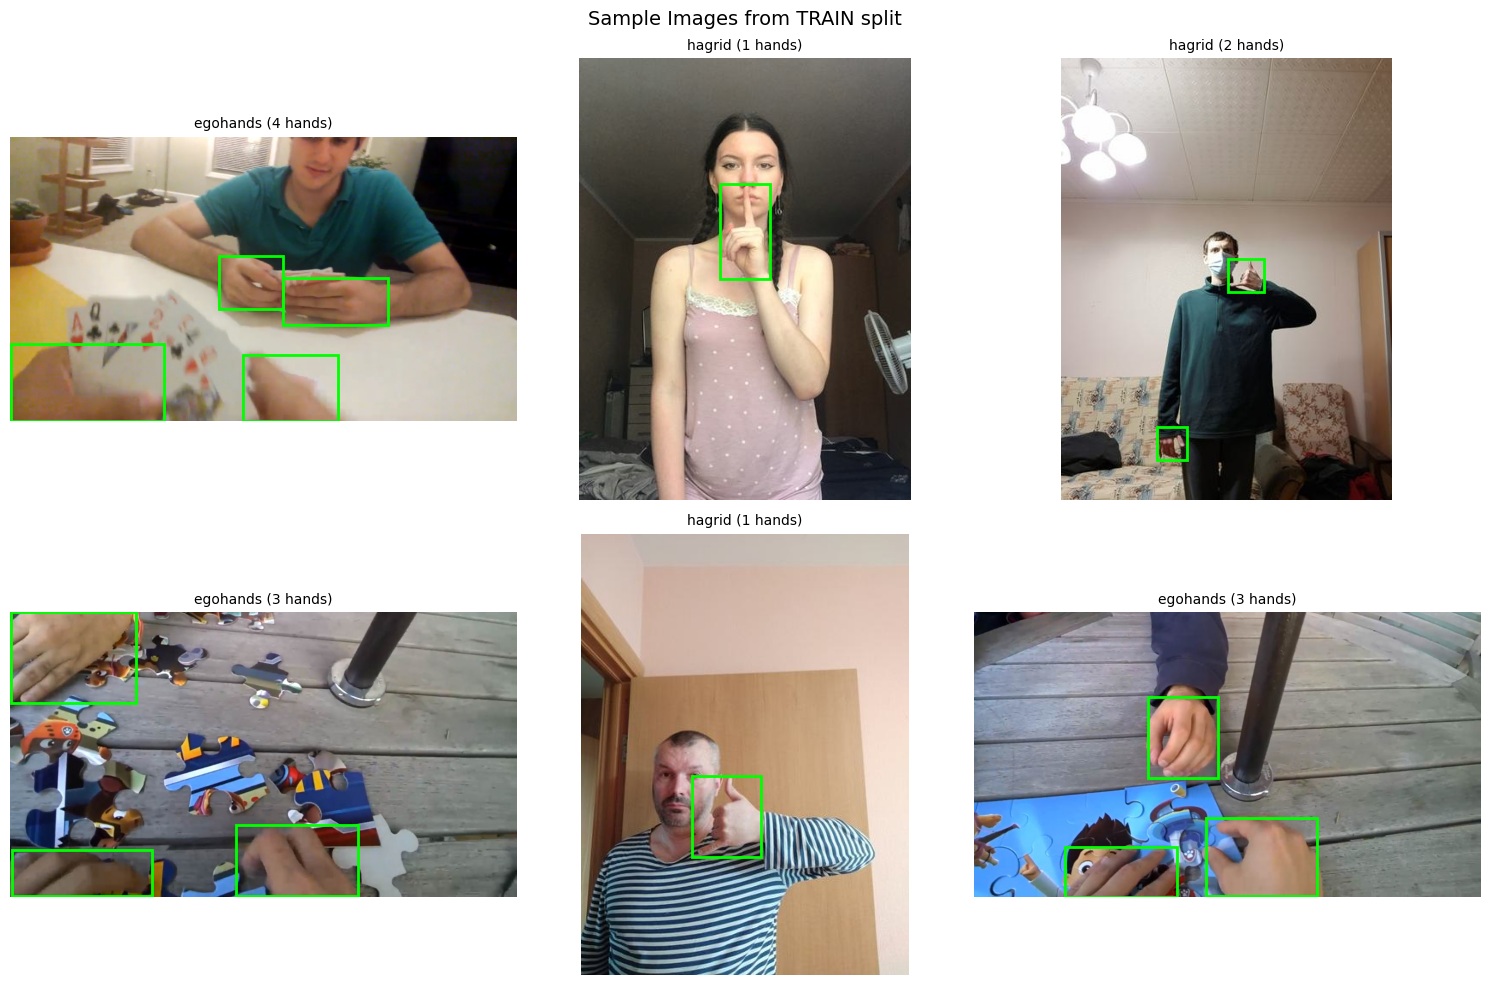


VAL samples:


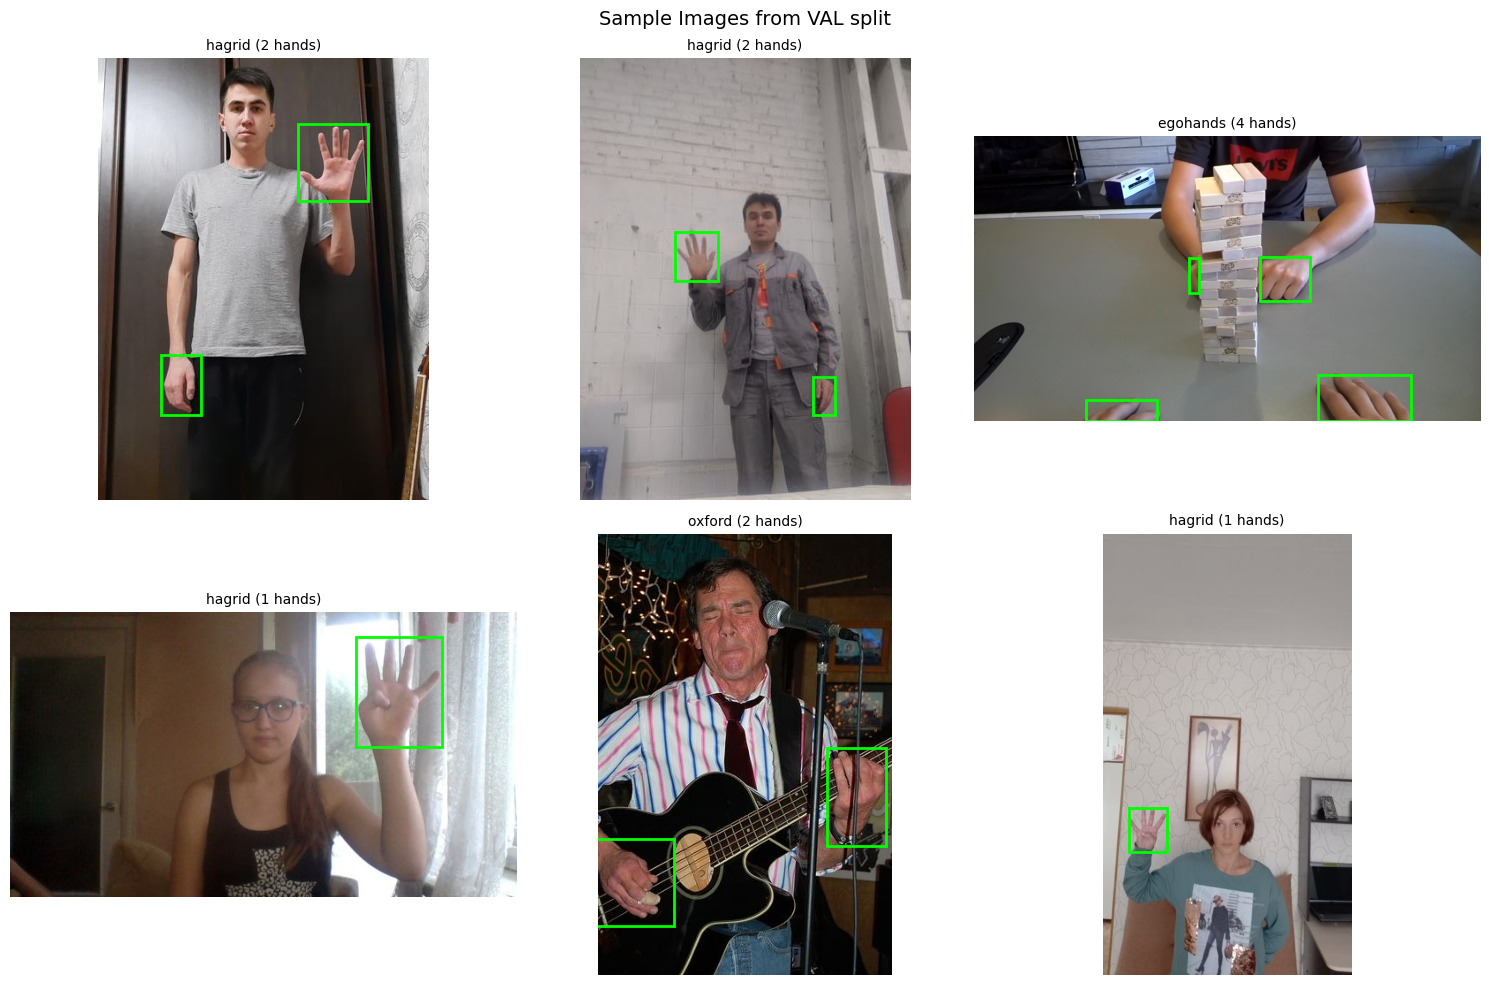


TEST samples:


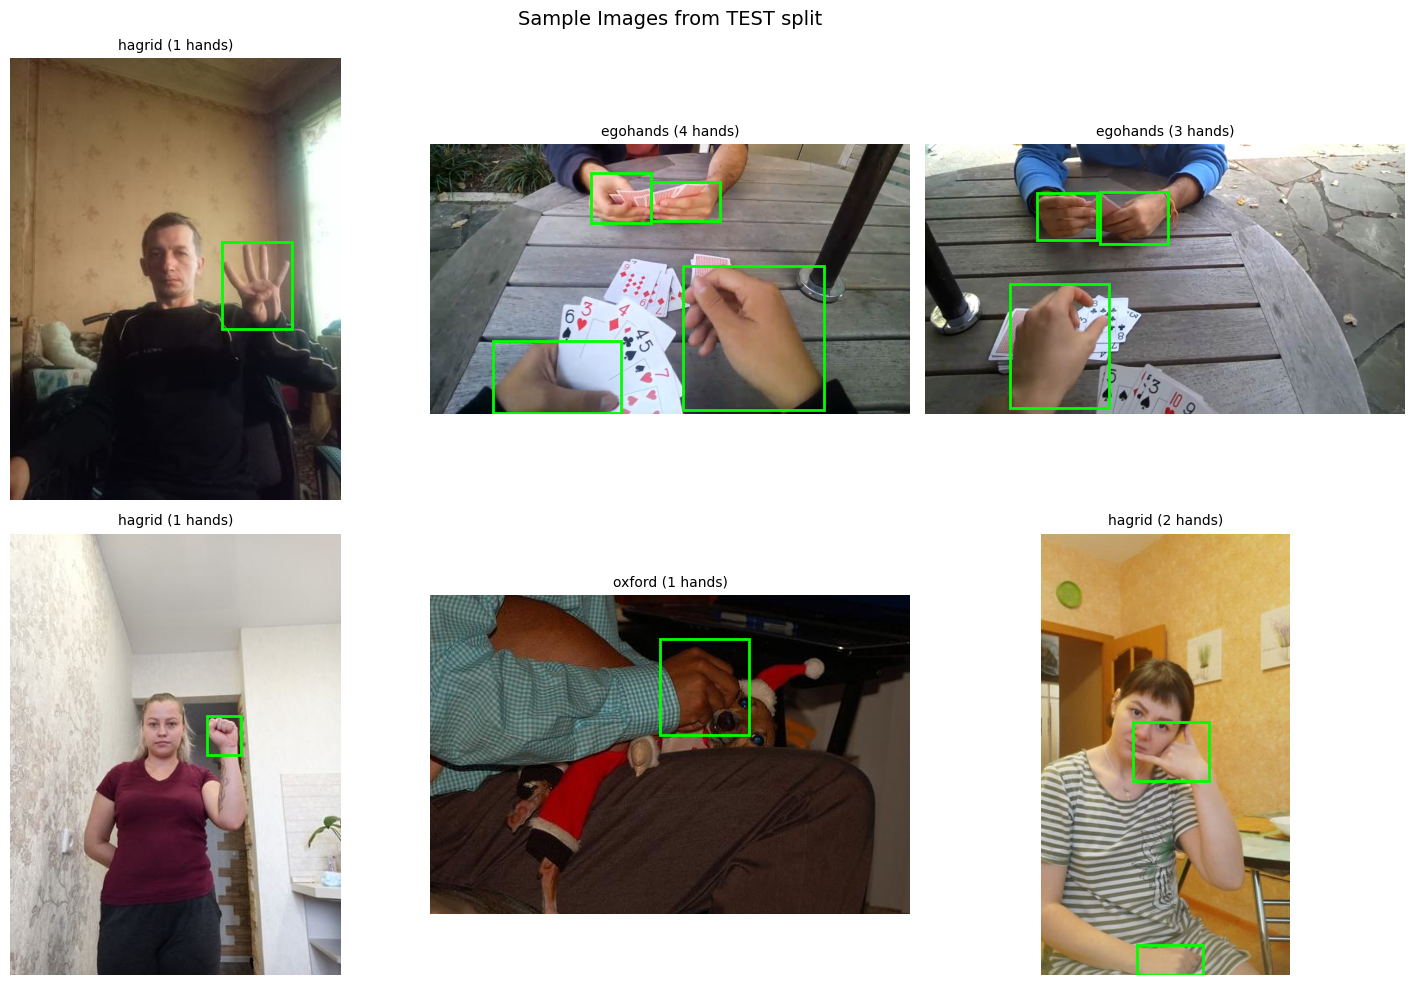

In [18]:
# ============================================================================
# 5.1 Visualize Sample Images with Bounding Boxes
# ============================================================================
def visualize_samples(split: str = "train", n_samples: int = 6, figsize: Tuple = (15, 10)):
    """Visualize random samples from a split with their bounding boxes."""
    
    img_dir = YOLO_DIR / "images" / split
    lbl_dir = YOLO_DIR / "labels" / split
    
    # Get all images
    img_paths = list(img_dir.glob("*.[jJ][pP][gG]")) + \
                list(img_dir.glob("*.[pP][nN][gG]")) + \
                list(img_dir.glob("*.[jJ][pP][eE][gG]"))
    
    if len(img_paths) == 0:
        print(f"No images found in {img_dir}")
        return
    
    # Sample random images
    n_samples = min(n_samples, len(img_paths))
    sample_paths = random.sample(img_paths, n_samples)
    
    # Create figure
    cols = 3
    rows = (n_samples + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten() if n_samples > 1 else [axes]
    
    for ax, img_path in zip(axes, sample_paths):
        # Read image
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_h, img_w = img.shape[:2]
        
        # Read labels
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        boxes = []
        if lbl_path.exists():
            with open(lbl_path, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        _, cx, cy, w, h = map(float, parts)
                        boxes.append((cx, cy, w, h))
        
        # Display image
        ax.imshow(img)
        
        # Draw boxes
        for (cx, cy, w, h) in boxes:
            # Convert to pixel coordinates
            x1 = (cx - w/2) * img_w
            y1 = (cy - h/2) * img_h
            box_w = w * img_w
            box_h = h * img_h
            
            rect = Rectangle((x1, y1), box_w, box_h, 
                            linewidth=2, edgecolor='lime', facecolor='none')
            ax.add_patch(rect)
        
        # Extract source from filename
        source = img_path.stem.split("_")[0]
        ax.set_title(f"{source} ({len(boxes)} hands)", fontsize=10)
        ax.axis("off")
    
    # Hide unused axes
    for ax in axes[n_samples:]:
        ax.axis("off")
    
    plt.suptitle(f"Sample Images from {split.upper()} split", fontsize=14)
    plt.tight_layout()
    plt.show()
# Visualize samples from each split
print("TRAIN samples:")
visualize_samples("train", n_samples=6)
print("\nVAL samples:")
visualize_samples("val", n_samples=6)
print("\nTEST samples:")
visualize_samples("test", n_samples=6)

DATASET STATISTICS

TRAIN:
  Images: 10577
  Total boxes: 20393
  Avg boxes/image: 1.93
  Min/Max boxes/image: 1/6
  Avg box size (w×h): 0.158 × 0.193
  Sources: {'egohands': 3829, 'hagrid': 6400, 'oxford': 348}

VAL:
  Images: 1321
  Total boxes: 2551
  Avg boxes/image: 1.93
  Min/Max boxes/image: 1/4
  Avg box size (w×h): 0.159 × 0.194
  Sources: {'oxford': 43, 'hagrid': 800, 'egohands': 478}

TEST:
  Images: 1325
  Total boxes: 2562
  Avg boxes/image: 1.93
  Min/Max boxes/image: 1/4
  Avg box size (w×h): 0.154 × 0.192
  Sources: {'hagrid': 800, 'oxford': 45, 'egohands': 480}


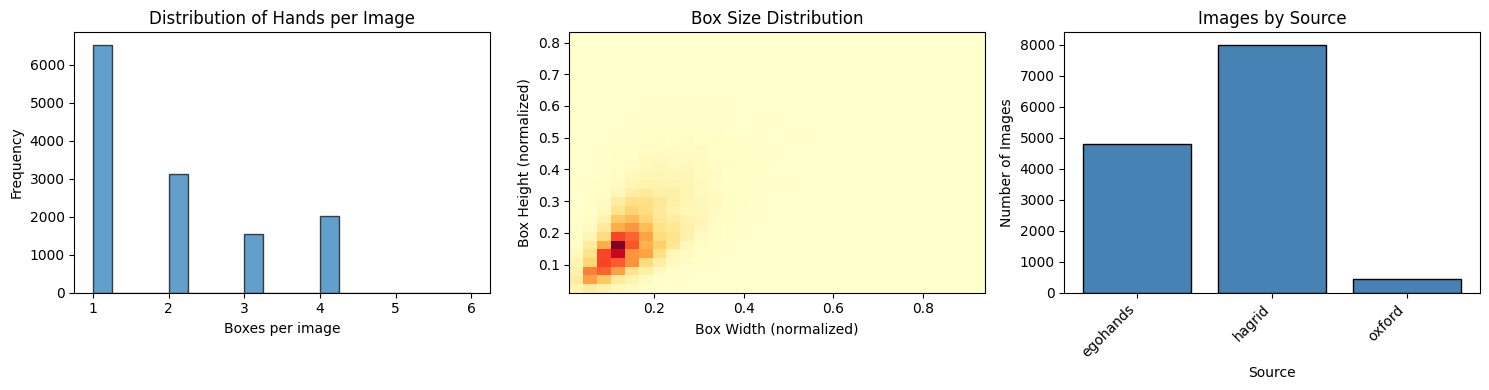

In [19]:
# ============================================================================
# 5.2 Dataset Statistics
# ============================================================================
def compute_dataset_stats():
    """Compute and display comprehensive dataset statistics."""
    
    stats = {}
    
    for split in ["train", "val", "test"]:
        lbl_dir = YOLO_DIR / "labels" / split
        img_dir = YOLO_DIR / "images" / split
        
        label_files = list(lbl_dir.glob("*.txt"))
        
        total_boxes = 0
        boxes_per_image = []
        box_sizes = []  # (width, height)
        sources = {}
        
        for lbl_path in label_files:
            # Count source
            source = lbl_path.stem.split("_")[0]
            sources[source] = sources.get(source, 0) + 1
            
            # Read boxes
            with open(lbl_path, "r") as f:
                boxes = []
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        _, cx, cy, w, h = map(float, parts)
                        boxes.append((w, h))
                        box_sizes.append((w, h))
                
                total_boxes += len(boxes)
                boxes_per_image.append(len(boxes))
        
        stats[split] = {
            "n_images": len(label_files),
            "n_boxes": total_boxes,
            "boxes_per_image": boxes_per_image,
            "box_sizes": box_sizes,
            "sources": sources
        }
    
    # Display statistics
    print("="*70)
    print("DATASET STATISTICS")
    print("="*70)
    
    for split, s in stats.items():
        print(f"\n{split.upper()}:")
        print(f"  Images: {s['n_images']}")
        print(f"  Total boxes: {s['n_boxes']}")
        print(f"  Avg boxes/image: {np.mean(s['boxes_per_image']):.2f}")
        print(f"  Min/Max boxes/image: {min(s['boxes_per_image'])}/{max(s['boxes_per_image'])}")
        
        if s['box_sizes']:
            widths = [b[0] for b in s['box_sizes']]
            heights = [b[1] for b in s['box_sizes']]
            print(f"  Avg box size (w×h): {np.mean(widths):.3f} × {np.mean(heights):.3f}")
        
        print(f"  Sources: {s['sources']}")
    
    # Plot distributions
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Boxes per image distribution
    all_boxes_per_img = []
    for s in stats.values():
        all_boxes_per_img.extend(s['boxes_per_image'])
    
    axes[0].hist(all_boxes_per_img, bins=20, edgecolor='black', alpha=0.7)
    axes[0].set_xlabel("Boxes per image")
    axes[0].set_ylabel("Frequency")
    axes[0].set_title("Distribution of Hands per Image")
    
    # Box size distribution
    all_widths = []
    all_heights = []
    for s in stats.values():
        all_widths.extend([b[0] for b in s['box_sizes']])
        all_heights.extend([b[1] for b in s['box_sizes']])
    
    axes[1].hist2d(all_widths, all_heights, bins=30, cmap='YlOrRd')
    axes[1].set_xlabel("Box Width (normalized)")
    axes[1].set_ylabel("Box Height (normalized)")
    axes[1].set_title("Box Size Distribution")
    
    # Source distribution
    all_sources = {}
    for s in stats.values():
        for src, cnt in s['sources'].items():
            all_sources[src] = all_sources.get(src, 0) + cnt
    
    axes[2].bar(all_sources.keys(), all_sources.values(), color='steelblue', edgecolor='black')
    axes[2].set_xlabel("Source")
    axes[2].set_ylabel("Number of Images")
    axes[2].set_title("Images by Source")
    plt.xticks(rotation=45, ha='right')
    
    plt.tight_layout()
    plt.show()
    
    return stats
dataset_stats = compute_dataset_stats()

###  6. Training Configuration

In [20]:
# ============================================================================
# 6.1 Define Training Experiments
# ============================================================================
# You can define multiple experiments to compare
EXPERIMENTS = [
    {
        "name": "yolov8n_mixed_v2",
        "model": "yolov8n.pt",
        "lr0": 0.01,
        "description": "YOLOv8 Nano with default LR"
    },
    {
        "name": "yolov8n_mixed_lowlr_v2",
        "model": "yolov8n.pt",
        "lr0": 0.001,
        "description": "YOLOv8 Nano with lower LR"
    },
    # Uncomment to try other configurations:
    # {
    #     "name": "yolov8n_mixed_lowlr",
    #     "model": "yolov8n.pt",
    #     "lr0": 0.001,
    #     "description": "YOLOv8 Nano with lower LR"
    # },
    # {
    #     "name": "yolov8s_mixed",
    #     "model": "yolov8s.pt",
    #     "lr0": 0.01,
    #     "description": "YOLOv8 Small"
    # },
    # {
    #     "name": "yolo11n_mixed",
    #     "model": "yolo11n.pt",
    #     "lr0": 0.01,
    #     "description": "YOLO11 Nano"
    # },
]
print("="*60)
print("TRAINING EXPERIMENTS")
print("="*60)
for i, exp in enumerate(EXPERIMENTS):
    print(f"\n{i+1}. {exp['name']}")
    print(f"   Model: {exp['model']}")
    print(f"   Learning rate: {exp['lr0']}")
    print(f"   Description: {exp['description']}")
print(f"\nCommon settings:")
print(f"  Image size: {TRAINING_CONFIG['img_size']}")
print(f"  Batch size: {TRAINING_CONFIG['batch_size']}")
print(f"  Epochs: {TRAINING_CONFIG['epochs']}")
print(f"  Early stopping patience: {TRAINING_CONFIG['patience']}")

TRAINING EXPERIMENTS

1. yolov8n_mixed_v2
   Model: yolov8n.pt
   Learning rate: 0.01
   Description: YOLOv8 Nano with default LR

2. yolov8n_mixed_lowlr_v2
   Model: yolov8n.pt
   Learning rate: 0.001
   Description: YOLOv8 Nano with lower LR

Common settings:
  Image size: 640
  Batch size: 16
  Epochs: 100
  Early stopping patience: 20


###  7. Model Training

In [22]:
# ============================================================================
# 7.1 Training Function
# ============================================================================
def train_experiment(experiment: Dict, data_yaml: Path, output_dir: Path) -> Dict:
    """Train a single experiment and return results."""
    
    name = experiment["name"]
    model_name = experiment["model"]
    lr0 = experiment["lr0"]
    
    print("\n" + "="*70)
    print(f"TRAINING: {name}")
    print("="*70)
    print(f"Model: {model_name}")
    print(f"Learning rate: {lr0}")
    print(f"Data: {data_yaml}")
    
    # Initialize model
    model = YOLO(model_name)
    
    # Train
    results = model.train(
        data=str(data_yaml),
        imgsz=TRAINING_CONFIG["img_size"],
        epochs=TRAINING_CONFIG["epochs"],
        batch=TRAINING_CONFIG["batch_size"],
        lr0=lr0,
        optimizer=TRAINING_CONFIG["optimizer"],
        patience=TRAINING_CONFIG["patience"],
        project=str(output_dir),
        name=name,
        exist_ok=True,
        verbose=True,
        plots=True,
        save=True,
    )
    
    # Get run directory
    run_dir = Path(results.save_dir)
    
    return {
        "name": name,
        "model": model,
        "run_dir": run_dir,
        "results": results
    }

In [18]:
# ============================================================================
# 7.2 Run All Experiments
# ============================================================================
trained_experiments = []
for experiment in EXPERIMENTS:
    result = train_experiment(
        experiment=experiment,
        data_yaml=DATA_YAML_PATH,
        output_dir=RUNS_DIR
    )
    trained_experiments.append(result)
    
    # Print summary
    print(f"\n✓ {result['name']} completed")
    print(f"  Run directory: {result['run_dir']}")
    print(f"  Best weights: {result['run_dir'] / 'weights' / 'best.pt'}")
print("\n" + "="*70)
print("ALL EXPERIMENTS COMPLETED")
print("="*70)


TRAINING: yolov8n_mixed_v2
Model: yolov8n.pt
Learning rate: 0.01
Data: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo/data.yaml
New https://pypi.org/project/ultralytics/8.3.250 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.248 🚀 Python-3.10.14 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 3769MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fract

### 8. Evaluation & Metrics

In [24]:
# ============================================================================
# 8.0 Load Already-Trained Models (Skip Training)
# ============================================================================
# Run this cell INSTEAD of Section 7 if you want to skip training
# and just re-run evaluation on existing models.
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import numpy as np
# Define paths (same as Section 1.2)
PROJECT_ROOT = Path.cwd() / "hand_bbox_baseline"
RUNS_DIR = PROJECT_ROOT / "runs"
YOLO_DIR = PROJECT_ROOT / "data" / "hands_yolo"
DATA_YAML_PATH = YOLO_DIR / "data.yaml"
# Discover all trained models in the runs directory
trained_experiments = []
# List of experiment names to evaluate (modify as needed)
experiment_names = [
    "yolov8n_mixed_v2",
    "yolov8n_mixed_lowlr",
    # Add other experiment folder names here
]
for name in experiment_names:
    run_dir = RUNS_DIR / name
    best_weights = run_dir / "weights" / "best.pt"
    
    if best_weights.exists():
        trained_experiments.append({
            "name": name,
            "run_dir": run_dir,
            "model": YOLO(str(best_weights)),
        })
        print(f"✓ Loaded: {name}")
        print(f"  Weights: {best_weights}")
    else:
        print(f"⚠️ Not found: {name} ({best_weights})")
print(f"\n✓ Loaded {len(trained_experiments)} trained models")

✓ Loaded: yolov8n_mixed_v2
  Weights: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/runs/yolov8n_mixed_v2/weights/best.pt
✓ Loaded: yolov8n_mixed_lowlr
  Weights: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/runs/yolov8n_mixed_lowlr/weights/best.pt

✓ Loaded 2 trained models


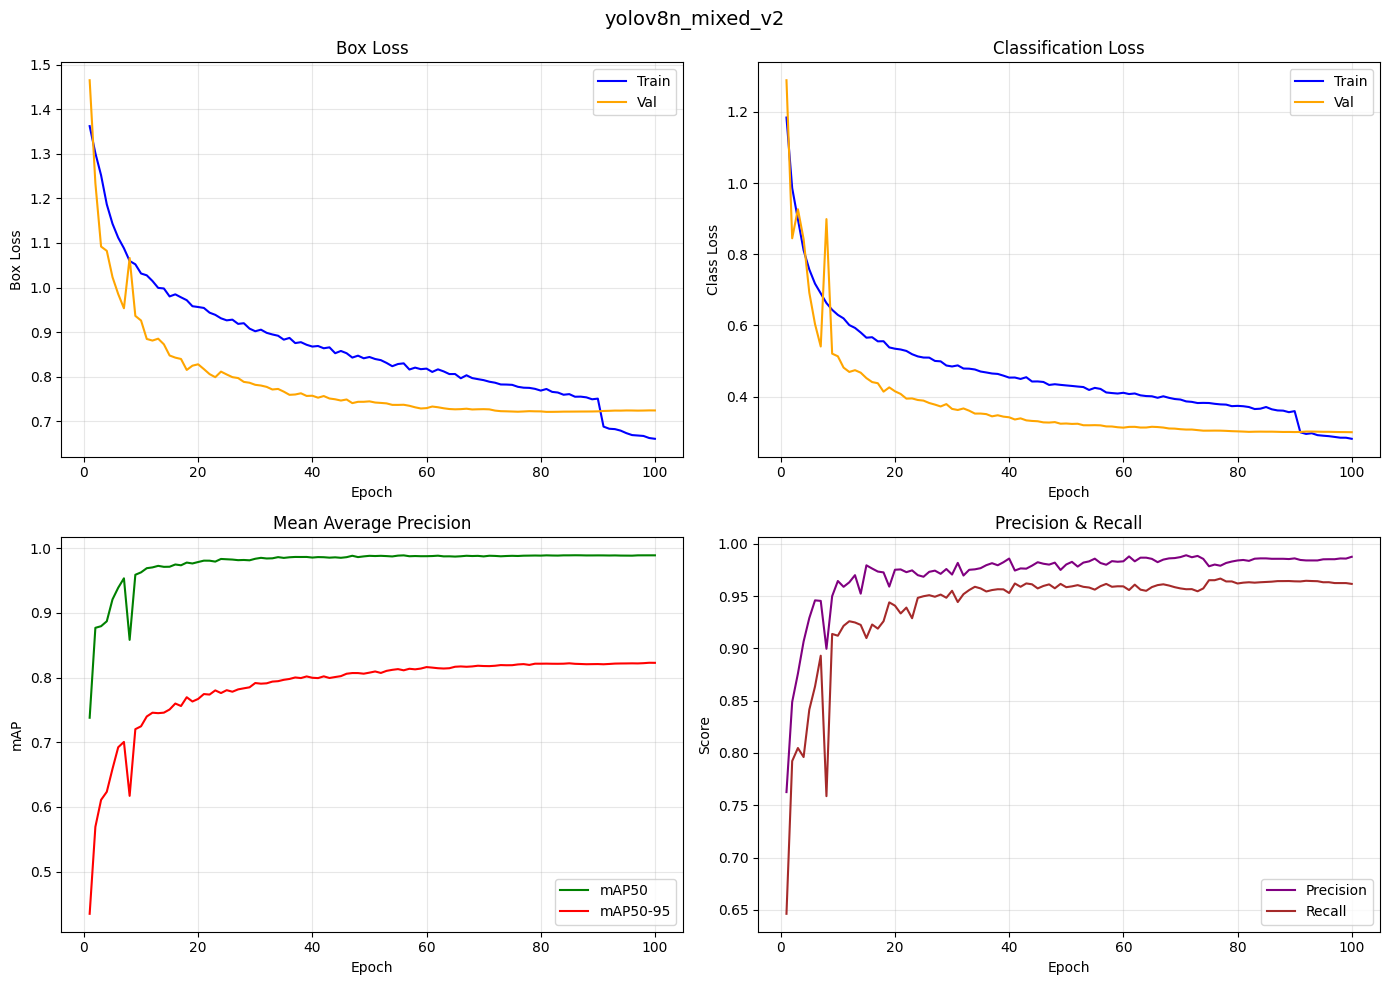


Final metrics for yolov8n_mixed_v2:
  train/box_loss: 0.6609
  train/cls_loss: 0.2814
  train/dfl_loss: 0.9247
  metrics/precision(B): 0.9875
  metrics/recall(B): 0.9616
  metrics/mAP50(B): 0.9890
  metrics/mAP50-95(B): 0.8228
  val/box_loss: 0.7245
  val/cls_loss: 0.2999
  val/dfl_loss: 0.9489


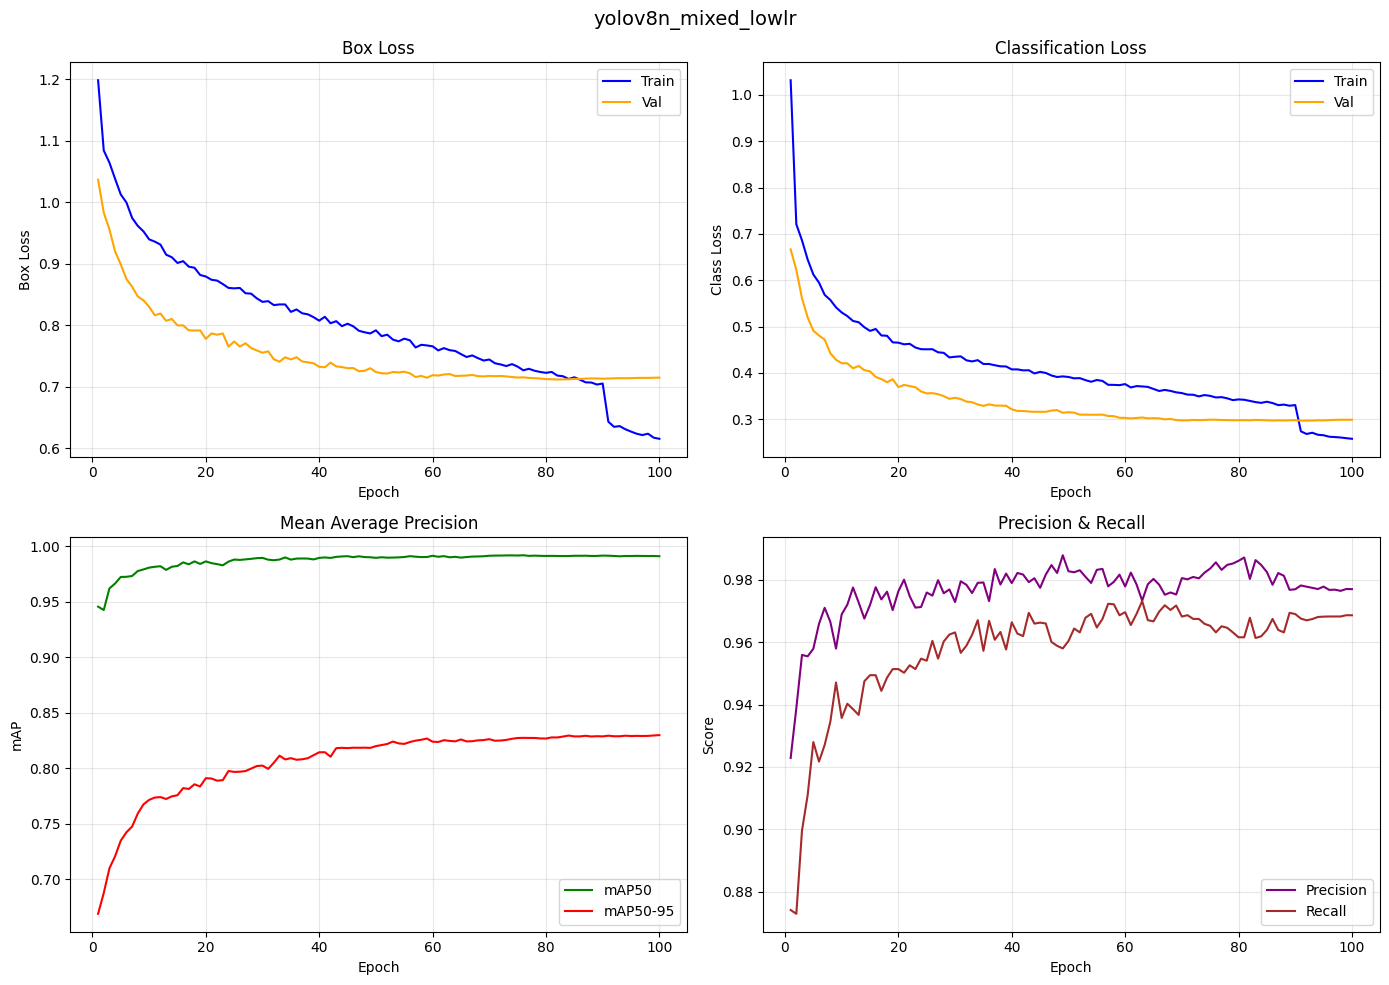


Final metrics for yolov8n_mixed_lowlr:
  train/box_loss: 0.6155
  train/cls_loss: 0.2580
  train/dfl_loss: 0.8830
  metrics/precision(B): 0.9770
  metrics/recall(B): 0.9686
  metrics/mAP50(B): 0.9910
  metrics/mAP50-95(B): 0.8298
  val/box_loss: 0.7149
  val/cls_loss: 0.2991
  val/dfl_loss: 0.9294


In [25]:
# ============================================================================
# 8.1 Plot Training Curves
# ============================================================================
def plot_training_curves(run_dir: Path, title: str = None):
    """Plot training curves from results.csv"""
    
    csv_path = run_dir / "results.csv"
    if not csv_path.exists():
        print(f"No results.csv found at {csv_path}")
        return
    
    df = pd.read_csv(csv_path)
    
    # Clean column names (remove leading spaces)
    df.columns = df.columns.str.strip()
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # Box loss
    if "train/box_loss" in df.columns:
        axes[0, 0].plot(df["epoch"], df["train/box_loss"], label="Train", color="blue")
    if "val/box_loss" in df.columns:
        axes[0, 0].plot(df["epoch"], df["val/box_loss"], label="Val", color="orange")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Box Loss")
    axes[0, 0].set_title("Box Loss")
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Class loss
    if "train/cls_loss" in df.columns:
        axes[0, 1].plot(df["epoch"], df["train/cls_loss"], label="Train", color="blue")
    if "val/cls_loss" in df.columns:
        axes[0, 1].plot(df["epoch"], df["val/cls_loss"], label="Val", color="orange")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Class Loss")
    axes[0, 1].set_title("Classification Loss")
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # mAP50
    if "metrics/mAP50(B)" in df.columns:
        axes[1, 0].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50", color="green")
    if "metrics/mAP50-95(B)" in df.columns:
        axes[1, 0].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95", color="red")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("mAP")
    axes[1, 0].set_title("Mean Average Precision")
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Precision & Recall
    if "metrics/precision(B)" in df.columns:
        axes[1, 1].plot(df["epoch"], df["metrics/precision(B)"], label="Precision", color="purple")
    if "metrics/recall(B)" in df.columns:
        axes[1, 1].plot(df["epoch"], df["metrics/recall(B)"], label="Recall", color="brown")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("Score")
    axes[1, 1].set_title("Precision & Recall")
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.suptitle(title or str(run_dir.name), fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # Print final metrics
    print(f"\nFinal metrics for {run_dir.name}:")
    final_row = df.iloc[-1]
    for col in df.columns:
        if "metrics" in col or "loss" in col:
            print(f"  {col}: {final_row[col]:.4f}")
# Plot curves for all experiments
for exp in trained_experiments:
    plot_training_curves(exp["run_dir"], title=exp["name"])

In [26]:
# ============================================================================
# 8.2 Evaluate on Test Set
# ============================================================================
def evaluate_model(model_path: Path, data_yaml: Path, split: str = "test"):
    """Evaluate model on a specific split."""
    
    model = YOLO(str(model_path))
    
    results = model.val(
        data=str(data_yaml),
        split=split,
        verbose=True
    )
    
    return results
# Evaluate all trained models
print("="*70)
print("TEST SET EVALUATION")
print("="*70)
evaluation_results = []
for exp in trained_experiments:
    best_weights = exp["run_dir"] / "weights" / "best.pt"
    
    if best_weights.exists():
        print(f"\nEvaluating {exp['name']}...")
        results = evaluate_model(best_weights, DATA_YAML_PATH, split="test")
        
        evaluation_results.append({
            "name": exp["name"],
            "mAP50": results.box.map50,
            "mAP50-95": results.box.map,
            "precision": results.box.mp,
            "recall": results.box.mr,
        })
    else:
        print(f"⚠️ No weights found for {exp['name']}")
# Summary table
if evaluation_results:
    print("\n" + "="*70)
    print("EVALUATION SUMMARY")
    print("="*70)
    
    df_results = pd.DataFrame(evaluation_results)
    print(df_results.to_string(index=False))
    
    # Save results
    results_path = RUNS_DIR / "evaluation_results.csv"
    df_results.to_csv(results_path, index=False)
    print(f"\n✓ Results saved to {results_path}")

TEST SET EVALUATION

Evaluating yolov8n_mixed_v2...
Ultralytics 8.3.248 🚀 Python-3.10.14 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 3769MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3247.8±2524.8 MB/s, size: 156.6 KB)
val: Scanning /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo/labels/test... 1325 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1325/1325 2.2Kit/s 0.6s0.1s
val: New cache created: /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 83/83 10.8it/s 7.7s0.1s
                   all       1325       2562      0.977      0.963       0.99      0.817
Speed: 0.4ms preprocess, 3.9ms inference, 0.0ms loss, 0.3ms postproc

In [27]:
# ============================================================================
# 8.3 Comprehensive Metrics Evaluation
# ============================================================================
import numpy as np
from pathlib import Path
def compute_iou(box1, box2):
    """Compute IoU between two boxes [x1,y1,x2,y2]"""
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
    
    inter_area = max(0, x2 - x1) * max(0, y2 - y1)
    
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    
    union_area = box1_area + box2_area - inter_area
    
    if union_area <= 0:
        return 0.0
    
    return inter_area / union_area
def compute_comprehensive_metrics(model_path: Path, data_yaml: Path, split: str = "test"):
    """
    Compute comprehensive metrics for model evaluation including:
    - Standard YOLO metrics (mAP, Precision, Recall)
    - IoU statistics (mean, median, std)
    - Inference speed metrics
    - Model complexity metrics
    """
    from ultralytics import YOLO
    import time
    
    model = YOLO(str(model_path))
    
    # Get model info - safely handle the case where info() returns None
    n_params = sum(p.numel() for p in model.model.parameters())
    
    # Try to get GFLOPs safely
    gflops = None
    try:
        info_result = model.info(verbose=False)
        if info_result is not None and len(info_result) > 1:
            gflops = info_result[1]
    except Exception:
        pass
    
    model_info = {
        "parameters": n_params,
        "parameters_M": n_params / 1e6,
        "gflops": gflops,
    }
    
    # Run validation to get standard metrics
    results = model.val(data=str(data_yaml), split=split, verbose=False)
    
    # Standard metrics
    standard_metrics = {
        "mAP50": results.box.map50,
        "mAP50-95": results.box.map,
        "precision": results.box.mp,
        "recall": results.box.mr,
    }
    
    # Compute IoU statistics by running predictions
    print("  Computing IoU statistics...")
    
    img_dir = YOLO_DIR / "images" / split
    lbl_dir = YOLO_DIR / "labels" / split
    
    all_ious = []
    inference_times = []
    
    img_paths = list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png"))
    
    for img_path in img_paths[:500]:  # Limit to 500 images for speed
        # Load ground truth
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        if not lbl_path.exists():
            continue
        
        gt_boxes = []
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    _, cx, cy, w, h = map(float, parts)
                    # Convert to x1,y1,x2,y2 normalized
                    x1 = cx - w/2
                    y1 = cy - h/2
                    x2 = cx + w/2
                    y2 = cy + h/2
                    gt_boxes.append([x1, y1, x2, y2])
        
        if not gt_boxes:
            continue
        
        # Run inference
        start_time = time.time()
        preds = model.predict(str(img_path), verbose=False, conf=0.25)
        inference_times.append(time.time() - start_time)
        
        pred = preds[0]
        if pred.boxes is None or len(pred.boxes) == 0:
            continue
        
        # Get predicted boxes (normalized)
        img_h, img_w = pred.orig_shape
        pred_boxes = []
        for box in pred.boxes:
            xyxy = box.xyxy[0].cpu().numpy()
            x1, y1, x2, y2 = xyxy
            pred_boxes.append([x1/img_w, y1/img_h, x2/img_w, y2/img_h])
        
        # Compute IoUs between predictions and ground truth
        for gt in gt_boxes:
            best_iou = 0
            for pb in pred_boxes:
                iou = compute_iou(gt, pb)
                best_iou = max(best_iou, iou)
            if best_iou > 0:
                all_ious.append(best_iou)
    
    # IoU statistics
    iou_stats = {}
    if all_ious:
        all_ious = np.array(all_ious)
        iou_stats = {
            "mean_iou": float(np.mean(all_ious)),
            "median_iou": float(np.median(all_ious)),
            "std_iou": float(np.std(all_ious)),
            "min_iou": float(np.min(all_ious)),
            "max_iou": float(np.max(all_ious)),
            "iou_75_percentile": float(np.percentile(all_ious, 75)),
            "iou_90_percentile": float(np.percentile(all_ious, 90)),
        }
    
    # Inference speed
    speed_stats = {}
    if inference_times:
        inference_times = np.array(inference_times)
        speed_stats = {
            "mean_inference_ms": float(np.mean(inference_times) * 1000),
            "std_inference_ms": float(np.std(inference_times) * 1000),
            "fps": float(1.0 / np.mean(inference_times)),
        }
    
    return {
        "model_info": model_info,
        "standard_metrics": standard_metrics,
        "iou_stats": iou_stats,
        "speed_stats": speed_stats,
    }
# Evaluate all trained models
print("="*70)
print("COMPREHENSIVE METRICS EVALUATION")
print("="*70)
all_metrics = {}
for exp in trained_experiments:
    name = exp["name"]
    best_weights = exp["run_dir"] / "weights" / "best.pt"
    
    if not best_weights.exists():
        print(f"Weights not found for {name}")
        continue
    
    print(f"\nEvaluating {name}...")
    metrics = compute_comprehensive_metrics(best_weights, DATA_YAML_PATH, split="test")
    all_metrics[name] = metrics
    
    print(f"\n  Model: {metrics['model_info']['parameters_M']:.2f}M parameters")
    if metrics['model_info']['gflops']:
        print(f"  GFLOPs: {metrics['model_info']['gflops']:.2f}")
    
    print(f"\n  Standard Metrics:")
    for k, v in metrics['standard_metrics'].items():
        print(f"    {k}: {v:.4f}")
    
    print(f"\n  IoU Statistics:")
    for k, v in metrics['iou_stats'].items():
        print(f"    {k}: {v:.4f}")
    
    print(f"\n  Speed:")
    for k, v in metrics['speed_stats'].items():
        print(f"    {k}: {v:.2f}")

COMPREHENSIVE METRICS EVALUATION

Evaluating yolov8n_mixed_v2...
Ultralytics 8.3.248 🚀 Python-3.10.14 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 3769MiB)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2207.5±1257.9 MB/s, size: 172.4 KB)
val: Scanning /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/data/hands_yolo/labels/test.cache... 1325 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1325/1325 1.9Mit/s 0.0s0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 83/83 10.4it/s 8.0s0.2s
                   all       1325       2562      0.977      0.963       0.99      0.817
Speed: 0.4ms preprocess, 4.0ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/fransando/Dev/tfg-sign-language-recognition/runs/detect/val7
  Computing IoU statistics...

  Model: 

In [28]:
# ============================================================================
# 8.4 Generate Comparison Table
# ============================================================================
# Create comprehensive comparison DataFrame
comparison_data = []
for name, metrics in all_metrics.items():
    row = {
        "Model": name,
        "Parameters (M)": metrics["model_info"]["parameters_M"],
        "mAP50": metrics["standard_metrics"]["mAP50"],
        "mAP50-95": metrics["standard_metrics"]["mAP50-95"],
        "Precision": metrics["standard_metrics"]["precision"],
        "Recall": metrics["standard_metrics"]["recall"],
        "Mean IoU": metrics["iou_stats"].get("mean_iou", None),
        "Median IoU": metrics["iou_stats"].get("median_iou", None),
        "IoU Std": metrics["iou_stats"].get("std_iou", None),
        "FPS": metrics["speed_stats"].get("fps", None),
        "Inference (ms)": metrics["speed_stats"].get("mean_inference_ms", None),
    }
    comparison_data.append(row)
df_comparison = pd.DataFrame(comparison_data)
# Display table
print("="*70)
print("MODEL COMPARISON TABLE")
print("="*70)
print(df_comparison.to_string(index=False))
# Save to CSV
comparison_path = RUNS_DIR / "model_comparison_comprehensive.csv"
df_comparison.to_csv(comparison_path, index=False)
print(f"\n✓ Saved to {comparison_path}")
# Also display as formatted table
print("\n" + "="*70)
print("FORMATTED RESULTS")
print("="*70)
for name, metrics in all_metrics.items():
    print(f"\n{name}:")
    print(f"  ├─ Parameters: {metrics['model_info']['parameters_M']:.2f}M")
    print(f"  ├─ mAP50: {metrics['standard_metrics']['mAP50']:.4f}")
    print(f"  ├─ mAP50-95: {metrics['standard_metrics']['mAP50-95']:.4f}")
    print(f"  ├─ Precision: {metrics['standard_metrics']['precision']:.4f}")
    print(f"  ├─ Recall: {metrics['standard_metrics']['recall']:.4f}")
    print(f"  ├─ Mean IoU: {metrics['iou_stats'].get('mean_iou', 'N/A'):.4f}")
    print(f"  ├─ Median IoU: {metrics['iou_stats'].get('median_iou', 'N/A'):.4f}")
    print(f"  ├─ FPS: {metrics['speed_stats'].get('fps', 'N/A'):.1f}")
    print(f"  └─ Inference: {metrics['speed_stats'].get('mean_inference_ms', 'N/A'):.2f}ms")

MODEL COMPARISON TABLE
              Model  Parameters (M)    mAP50  mAP50-95  Precision   Recall  Mean IoU  Median IoU  IoU Std        FPS  Inference (ms)
   yolov8n_mixed_v2        3.011043 0.989688  0.816709   0.976633 0.962529  0.882980    0.907875 0.106964 124.042526        8.061751
yolov8n_mixed_lowlr        3.011043 0.992487  0.827035   0.981470 0.971897  0.887066    0.910328 0.101279 128.986482        7.752750

✓ Saved to /home/fransando/Dev/tfg-sign-language-recognition/01_notebooks/hand_detection/hand_bbox_baseline/runs/model_comparison_comprehensive.csv

FORMATTED RESULTS

yolov8n_mixed_v2:
  ├─ Parameters: 3.01M
  ├─ mAP50: 0.9897
  ├─ mAP50-95: 0.8167
  ├─ Precision: 0.9766
  ├─ Recall: 0.9625
  ├─ Mean IoU: 0.8830
  ├─ Median IoU: 0.9079
  ├─ FPS: 124.0
  └─ Inference: 8.06ms

yolov8n_mixed_lowlr:
  ├─ Parameters: 3.01M
  ├─ mAP50: 0.9925
  ├─ mAP50-95: 0.8270
  ├─ Precision: 0.9815
  ├─ Recall: 0.9719
  ├─ Mean IoU: 0.8871
  ├─ Median IoU: 0.9103
  ├─ FPS: 129.0
  └─ Inf

### 9. Inference & Testing

Visualizing predictions from: yolov8n_mixed_v2


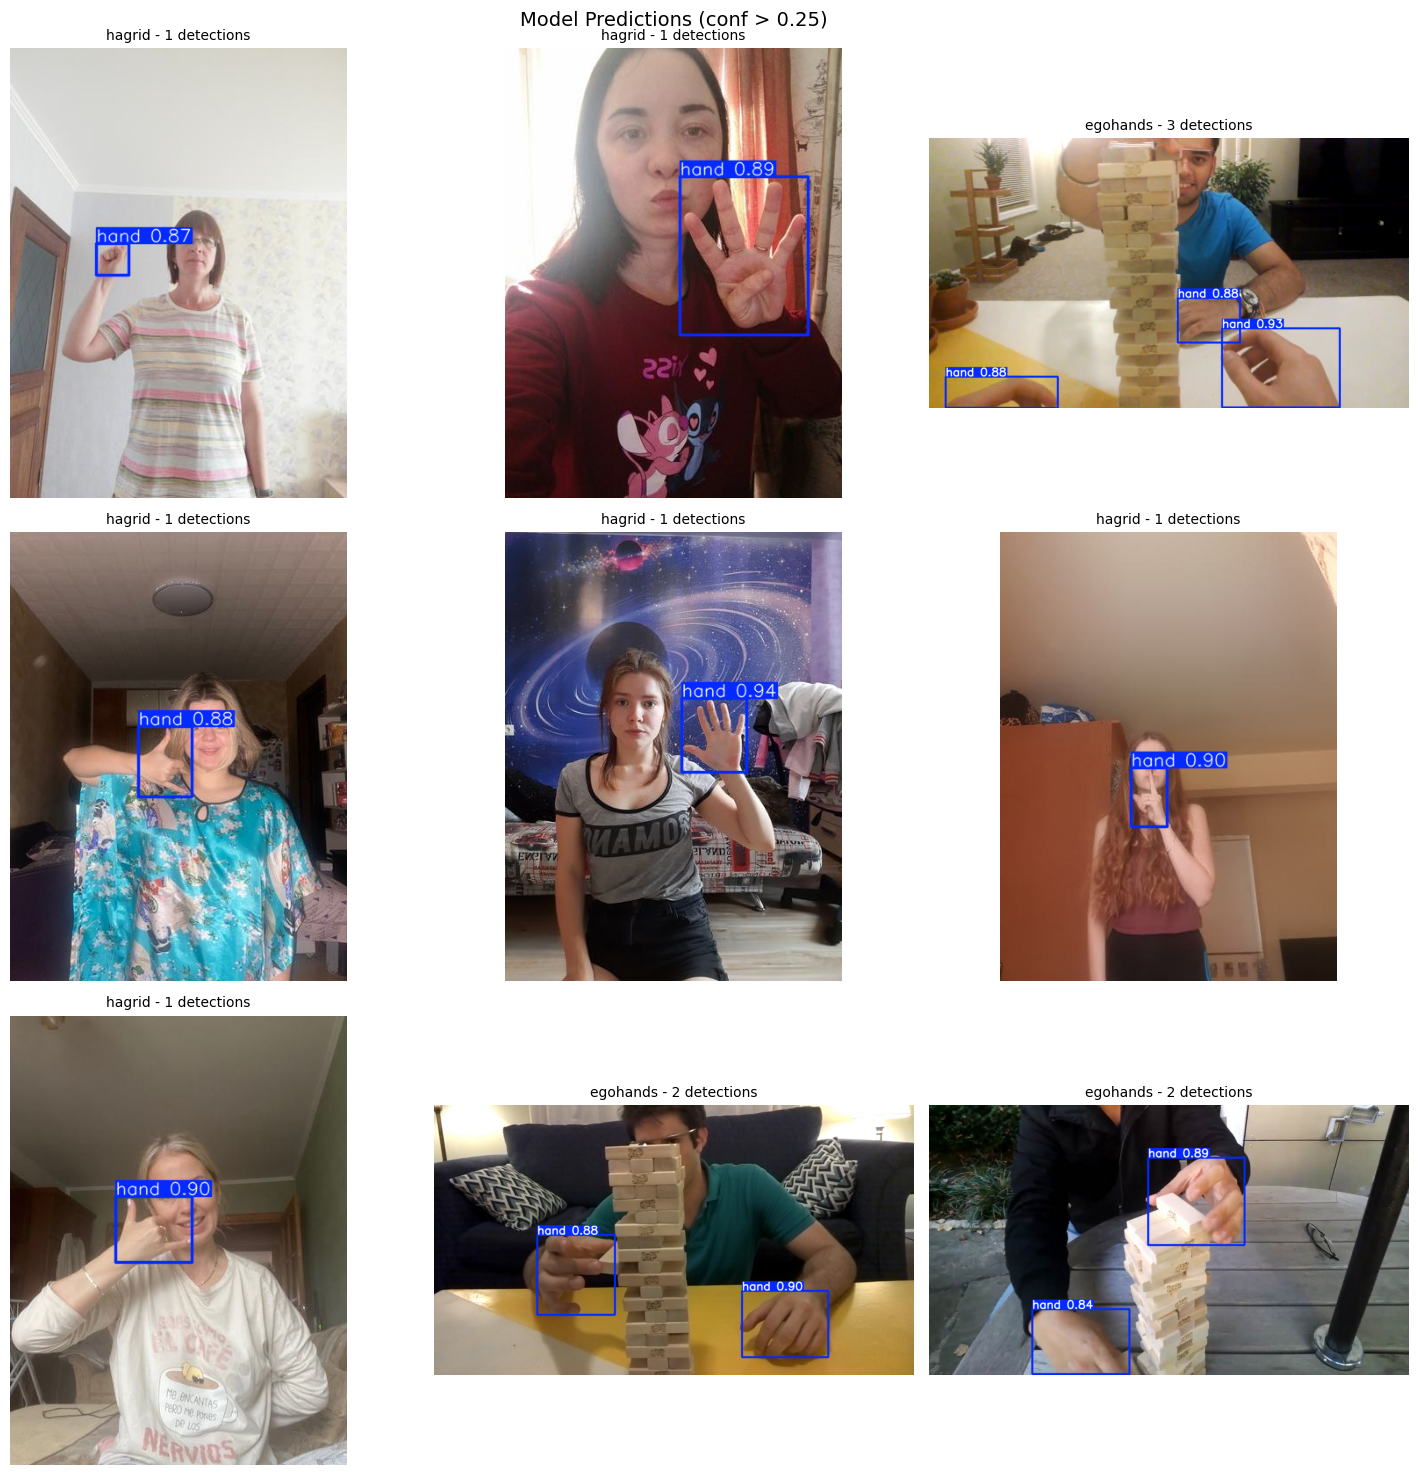

In [29]:
# ============================================================================
# 9.1 Run Inference on Test Images
# ============================================================================
def visualize_predictions(model_path: Path, n_images: int = 6, conf_threshold: float = 0.25):
    """Visualize model predictions on test images."""
    
    model = YOLO(str(model_path))
    
    # Get test images
    test_img_dir = YOLO_DIR / "images" / "test"
    img_paths = list(test_img_dir.glob("*.[jJ][pP][gG]")) + \
                list(test_img_dir.glob("*.[pP][nN][gG]"))
    
    if not img_paths:
        print("No test images found!")
        return
    
    # Sample random images
    n_images = min(n_images, len(img_paths))
    sample_paths = random.sample(img_paths, n_images)
    
    # Run predictions
    results = model.predict(
        source=sample_paths,
        conf=conf_threshold,
        verbose=False
    )
    
    # Visualize
    cols = 3
    rows = (n_images + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
    axes = axes.flatten() if n_images > 1 else [axes]
    
    for ax, result in zip(axes, results):
        # Get annotated image
        img_annotated = result.plot()
        img_rgb = cv2.cvtColor(img_annotated, cv2.COLOR_BGR2RGB)
        
        ax.imshow(img_rgb)
        
        # Count detections
        n_detections = len(result.boxes) if result.boxes is not None else 0
        source = Path(result.path).stem.split("_")[0]
        ax.set_title(f"{source} - {n_detections} detections", fontsize=10)
        ax.axis("off")
    
    # Hide unused axes
    for ax in axes[n_images:]:
        ax.axis("off")
    
    plt.suptitle(f"Model Predictions (conf > {conf_threshold})", fontsize=14)
    plt.tight_layout()
    plt.show()
# Visualize predictions from best model
if trained_experiments:
    best_exp = trained_experiments[0]  # Use first experiment
    best_weights = best_exp["run_dir"] / "weights" / "best.pt"
    
    if best_weights.exists():
        print(f"Visualizing predictions from: {best_exp['name']}")
        visualize_predictions(best_weights, n_images=9, conf_threshold=0.25)

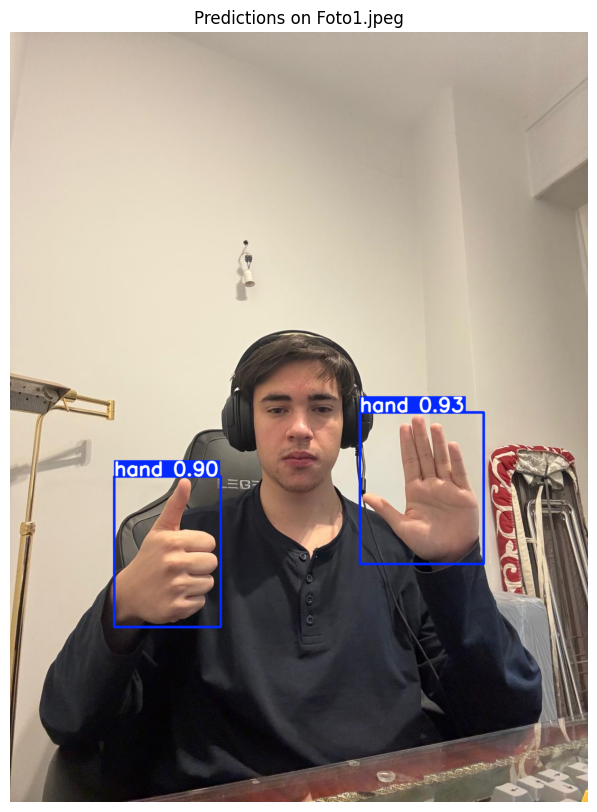


Detections (conf > 0.25):
  Hand 1: conf=0.930, bbox=['726.5', '790.3', '983.9', '1105.6']
  Hand 2: conf=0.899, bbox=['216.2', '923.1', '437.5', '1236.5']


In [30]:
# ============================================================================
# 9.2 Test on Custom Image (Optional)
# ============================================================================
def predict_on_image(model_path: Path, image_path: str, conf_threshold: float = 0.25):
    """Run prediction on a custom image."""
    
    image_path = Path(image_path)
    if not image_path.exists():
        print(f"Image not found: {image_path}")
        return
    
    model = YOLO(str(model_path))
    
    results = model.predict(
        source=str(image_path),
        conf=conf_threshold,
        verbose=False
    )
    
    # Display
    result = results[0]
    img_annotated = result.plot()
    img_rgb = cv2.cvtColor(img_annotated, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 10))
    plt.imshow(img_rgb)
    plt.title(f"Predictions on {image_path.name}")
    plt.axis("off")
    plt.show()
    
    # Print detections
    print(f"\nDetections (conf > {conf_threshold}):")
    if result.boxes is not None:
        for i, box in enumerate(result.boxes):
            conf = float(box.conf)
            xyxy = box.xyxy[0].tolist()
            print(f"  Hand {i+1}: conf={conf:.3f}, bbox={[f'{x:.1f}' for x in xyxy]}")
    else:
        print("  No hands detected")
    
    return results
# Example usage (uncomment and modify path):
if trained_experiments:
    best_weights = trained_experiments[1]["run_dir"] / "weights" / "best.pt"
    predict_on_image(best_weights, "/home/fransando/Dev/tfg-sign-language-recognition/05_experiments/testimages/Foto1.jpeg")

In [ ]:
# ============================================================================
# 9.3 Export Best Model
# ============================================================================
def export_model(model_path: Path, export_formats: List[str] = ["onnx"]):
    """Export model to different formats."""
    
    model = YOLO(str(model_path))
    
    for fmt in export_formats:
        print(f"\nExporting to {fmt}...")
        model.export(format=fmt)
        print(f"✓ Exported to {fmt}")
# Export best model (optional)
if trained_experiments:
    best_weights = trained_experiments[0]["run_dir"] / "weights" / "best.pt"
    
    if best_weights.exists():
        print("="*60)
        print("MODEL EXPORT")
        print("="*60)
        print(f"Best model: {best_weights}")
        
        # Uncomment to export:
        # export_model(best_weights, ["onnx", "torchscript"])

### 10. Summary & Next Step

 Training Complete!
The trained models are saved in:
- `runs/[experiment_name]/weights/best.pt` - Best checkpoint
- `runs/[experiment_name]/weights/last.pt` - Last checkpoint
 Next Steps:
1. **Compare perspectives**: Check if the model now performs better on third-person images
2. **Fine-tune**: Adjust hyperparameters if needed
3. **Add more data**: Enable HaGRID or other datasets for more variety
4. **Deploy**: Export to ONNX/TFLite for mobile deployment
 Tips for Better Generalization:
- Ensure balanced dataset across perspectives
- Use data augmentation (YOLO does this automatically)
- Try larger models (yolov8s, yolov8m) if you have GPU memory
- Consider test-time augmentation for inference

In [ ]:
# ============================================================================
# Final Summary
# ============================================================================
print("="*70)
print("TRAINING SUMMARY")
print("="*70)
print(f"\nDataset: {YOLO_DIR}")
print(f"  Train: {len(splits['train'])} images")
print(f"  Val: {len(splits['val'])} images")
print(f"  Test: {len(splits['test'])} images")
print(f"\nTrained models:")
for exp in trained_experiments:
    best_weights = exp["run_dir"] / "weights" / "best.pt"
    print(f"  {exp['name']}: {best_weights}")
print(f"\nResults saved to: {RUNS_DIR}")
print("\n✓ Done!")